# Agente de IA para el control de acceso a documentos médicos
**Centro de Salud Materno Infantil San Genaro de Villa** · Sistemas Inteligentes y Machine Learning (UPN)

Este notebook reproduce el desarrollo de la solución IA/ML descrita en el informe:

1. Generación del dataset sintético de eventos de acceso (sección 3.5).
2. Preprocesamiento (One-Hot Encoding, hora decimal, StandardScaler).
3. Entrenamiento de **Árbol de Decisión**, **Isolation Forest** y **Regresión Logística** con partición 70/15/15.
4. Evaluación del agente completo con los escenarios de la Tabla 3 y verificación de los criterios de éxito.

In [1]:
import os, sys, json
os.chdir('..') if os.path.basename(os.getcwd()) == 'notebooks' else None
sys.path.insert(0, os.getcwd())
import pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 160)

## 1. Dataset sintético
Cada fila es un **evento de acceso**. La decisión esperada se asigna con la matriz de roles y permisos *antes* de entrenar.

In [2]:
from src import generar_dataset
generar_dataset.main()
df = pd.read_csv('data/dataset_entrenamiento.csv')
df.head(8)

Dataset de entrenamiento: 7941 eventos
resultado_esperado
REQUIERE_APROBACION    2719
RECHAZAR               2637
AUTORIZAR              2585
Anomalías: 794 (10.0%)

Escenarios de evaluación: 330
grupo
legitima              100
no_autorizada         100
anomalia              100
excepcional            10
rol_medico              5
rol_enfermeria          5
rol_administrativo      5
rol_administrador       5


,id_evento,rol_usuario,tipo_documento,relacion_paciente,hora_acceso,autorizacion_excepcional,frecuencia_accesos,resultado_esperado,anomalia
0,E00001,enfermeria,resultado_laboratorio,sin_relacion,06:44,0,16,RECHAZAR,0
1,E00002,enfermeria,orden_medica,personal_apoyo,17:41,0,18,AUTORIZAR,0
2,E00003,enfermeria,orden_medica,personal_apoyo,16:51,0,2,AUTORIZAR,0
3,E00004,administrativo,resultado_laboratorio,personal_apoyo,09:00,0,10,RECHAZAR,0
4,E00005,administrador,historia_clinica,sin_relacion,09:28,1,6,REQUIERE_APROBACION,0
5,E00006,administrativo,orden_medica,sin_relacion,11:03,0,5,RECHAZAR,0
6,E00007,enfermeria,resultado_laboratorio,personal_apoyo,22:12,1,18,REQUIERE_APROBACION,0
7,E00008,administrativo,resultado_laboratorio,sin_relacion,08:49,1,8,REQUIERE_APROBACION,0


In [3]:
df['resultado_esperado'].value_counts(), df['anomalia'].mean().round(3)

(resultado_esperado
 REQUIERE_APROBACION    2719
 RECHAZAR               2637
 AUTORIZAR              2585
 Name: count, dtype: int64,
 np.float64(0.1))

## 2. Preprocesamiento
Variables categóricas con One-Hot Encoding, hora en formato decimal, frecuencia estandarizada y desviación respecto al rol.

In [4]:
from src.preprocesamiento import Preprocesador, FEATURES_ARBOL, FEATURES_ISOLATION, FEATURES_LOGISTICA
prep = Preprocesador().fit(df)
prep.transform(df.head(8))[FEATURES_LOGISTICA + ['desviacion_rol']]

,rol_medico,rol_enfermeria,rol_administrativo,rol_administrador,rel_medico_tratante,rel_personal_apoyo,rel_sin_relacion,autorizacion_excepcional,doc_historia_clinica,doc_resultado_laboratorio,doc_orden_medica,hora_num,fuera_horario,frecuencia_std,desviacion_rol
0,0,1,0,0,0,0,1,0,0,1,0,6.73,1,0.301,0.081
1,0,1,0,0,0,1,0,0,0,0,1,17.68,0,0.452,0.230
2,0,1,0,0,0,1,0,0,0,0,1,16.85,0,-0.754,-0.966
3,0,0,1,0,0,1,0,0,0,1,0,9.00,0,-0.151,-0.002
4,0,0,0,1,0,0,1,1,1,0,0,9.47,0,-0.452,-0.162
5,0,0,1,0,0,0,1,0,0,0,1,11.05,0,-0.528,-0.360
6,0,1,0,0,0,1,0,1,0,1,0,22.20,1,0.452,0.230
7,0,0,1,0,0,0,1,1,0,1,0,8.82,0,-0.302,-0.145


## 3. Entrenamiento de los tres modelos

In [5]:
from src import entrenar
entrenar.main()
m = json.load(open('reports/metricas_modelos.json', encoding='utf-8'))
resumen = pd.DataFrame({
    'Árbol de Decisión': {k: m['arbol_decision']['prueba'][k] for k in ['exactitud','precision_macro','recall_macro','f1_macro']},
    'Regresión Logística': {k: m['regresion_logistica']['prueba'][k] for k in ['exactitud','precision_macro','recall_macro','f1_macro']},
})
resumen

Partición  -> {'entrenamiento': 5558, 'validacion': 1191, 'prueba': 1192}
arbol_decision         exactitud=0.9765  precisión=0.9769  recall=0.9765  F1=0.9765
regresion_logistica    exactitud=0.9765  precisión=0.9769  recall=0.9765  F1=0.9765
isolation_forest       recall=0.9060  precisión=0.9217  F1=0.9138  FPR=0.0084  AUC=0.9946
Modelos guardados en /home/claude/proyecto/agente-ia/models


,Árbol de Decisión,Regresión Logística
exactitud,0.9765,0.9765
precision_macro,0.9769,0.9769
recall_macro,0.9765,0.9765
f1_macro,0.9765,0.9765


In [6]:
{k: v for k, v in m['isolation_forest']['prueba'].items() if k != 'matriz_confusion'}

{'recall_deteccion': 0.906,
 'precision': 0.9217,
 'f1': 0.9138,
 'tasa_falsos_positivos': 0.0084,
 'roc_auc': 0.9946}

In [7]:
pd.DataFrame(m['arbol_decision']['curva_validacion_max_depth'])

,max_depth,f1_entrenamiento,f1_validacion
0,2,0.6459,0.6453
1,3,0.7167,0.7155
2,4,0.8168,0.8091
3,5,0.9342,0.9386
4,6,0.9838,0.9841
5,7,0.9863,0.9874
6,8,0.9863,0.9874
7,10,0.9863,0.9874


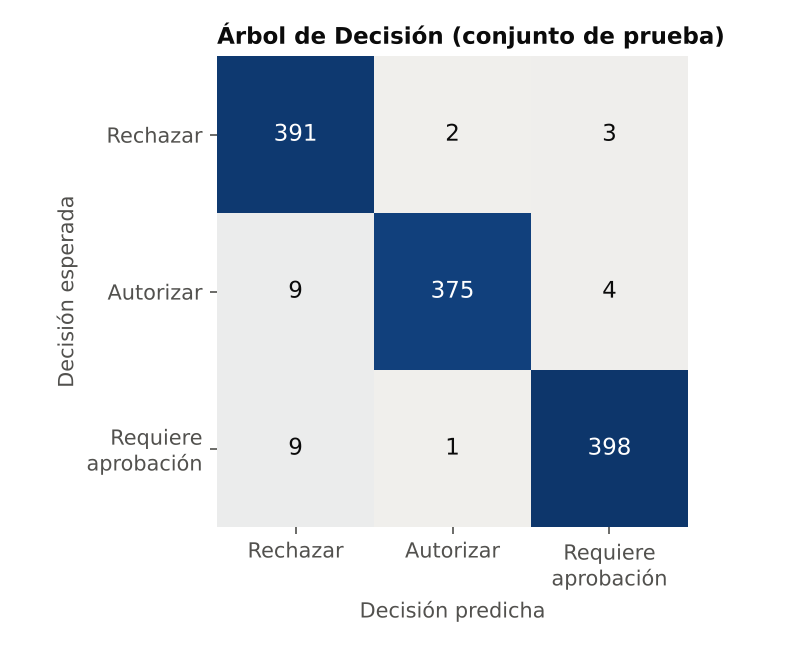

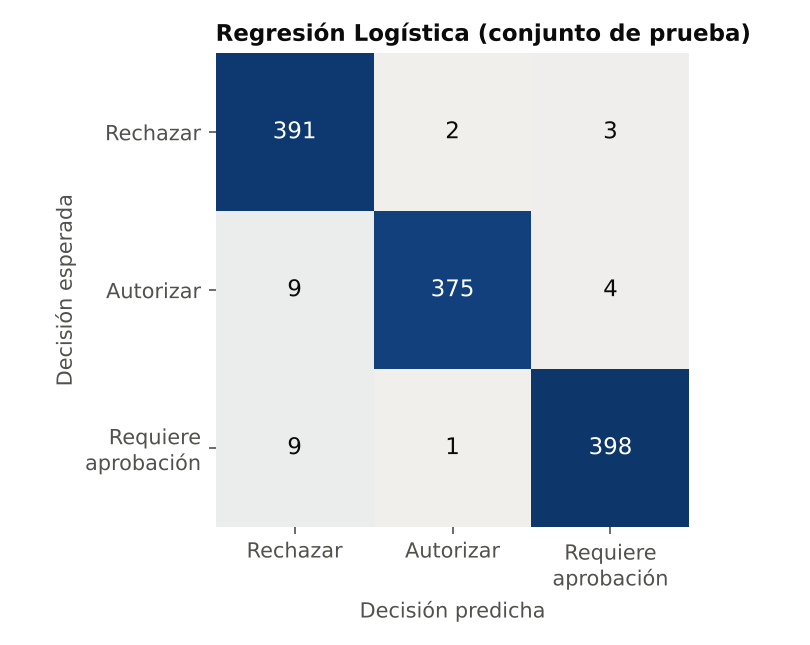

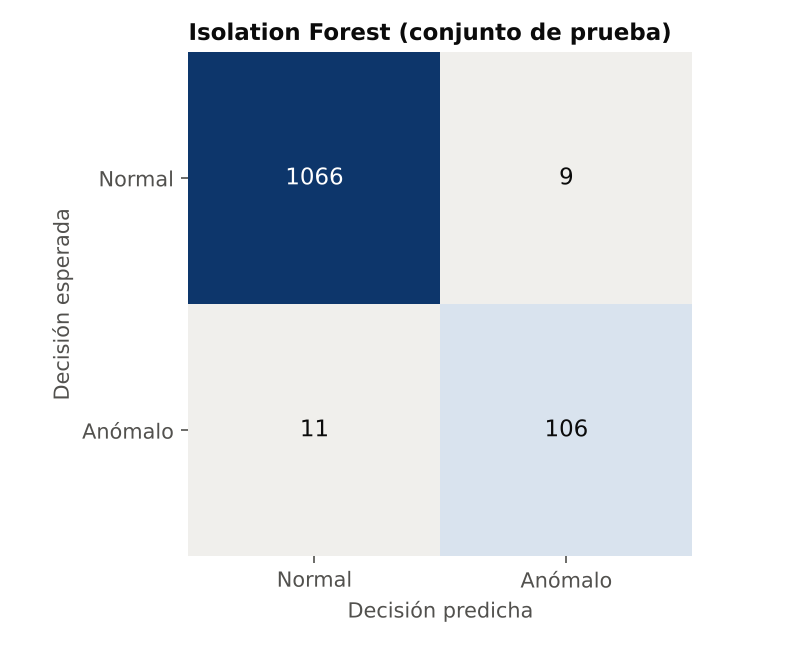

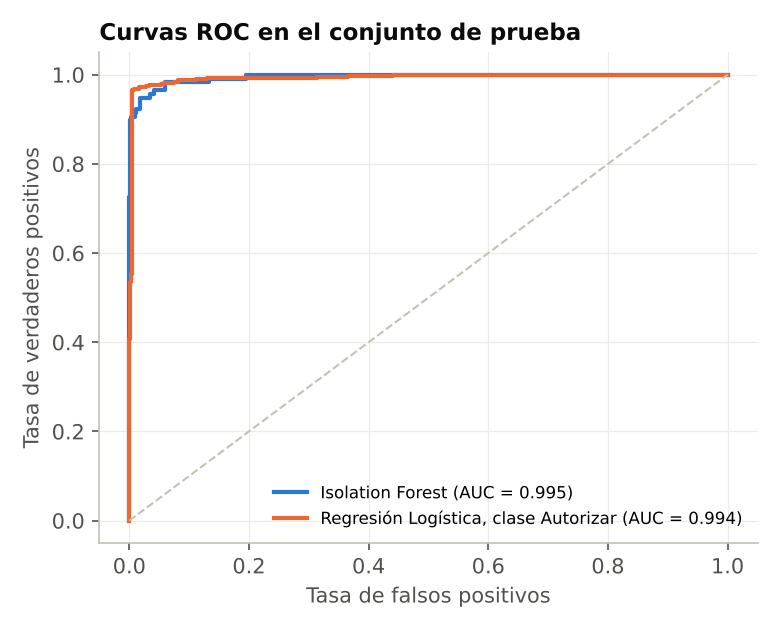

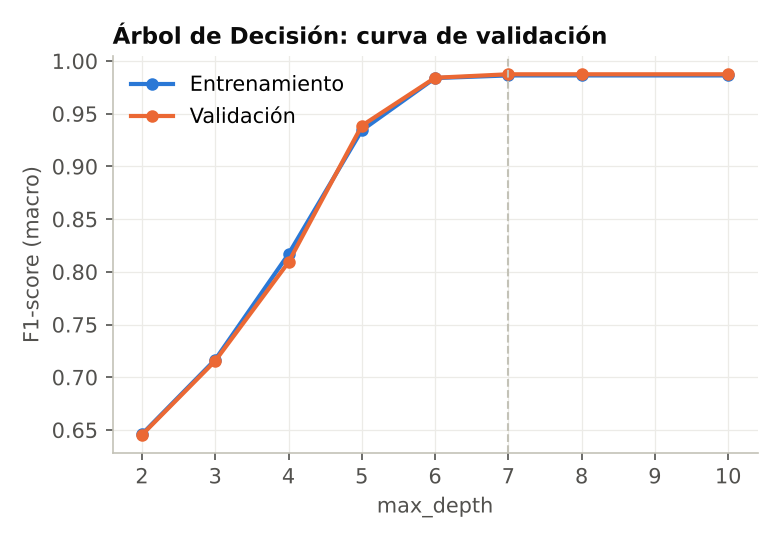

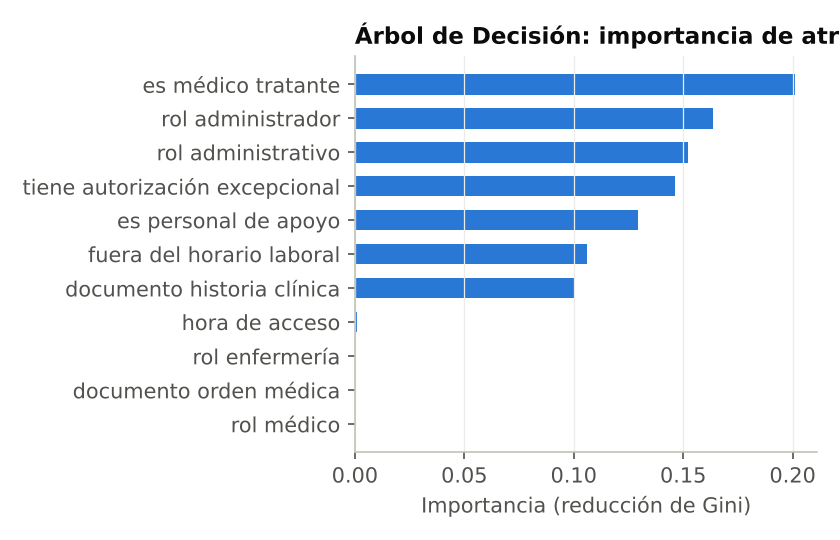

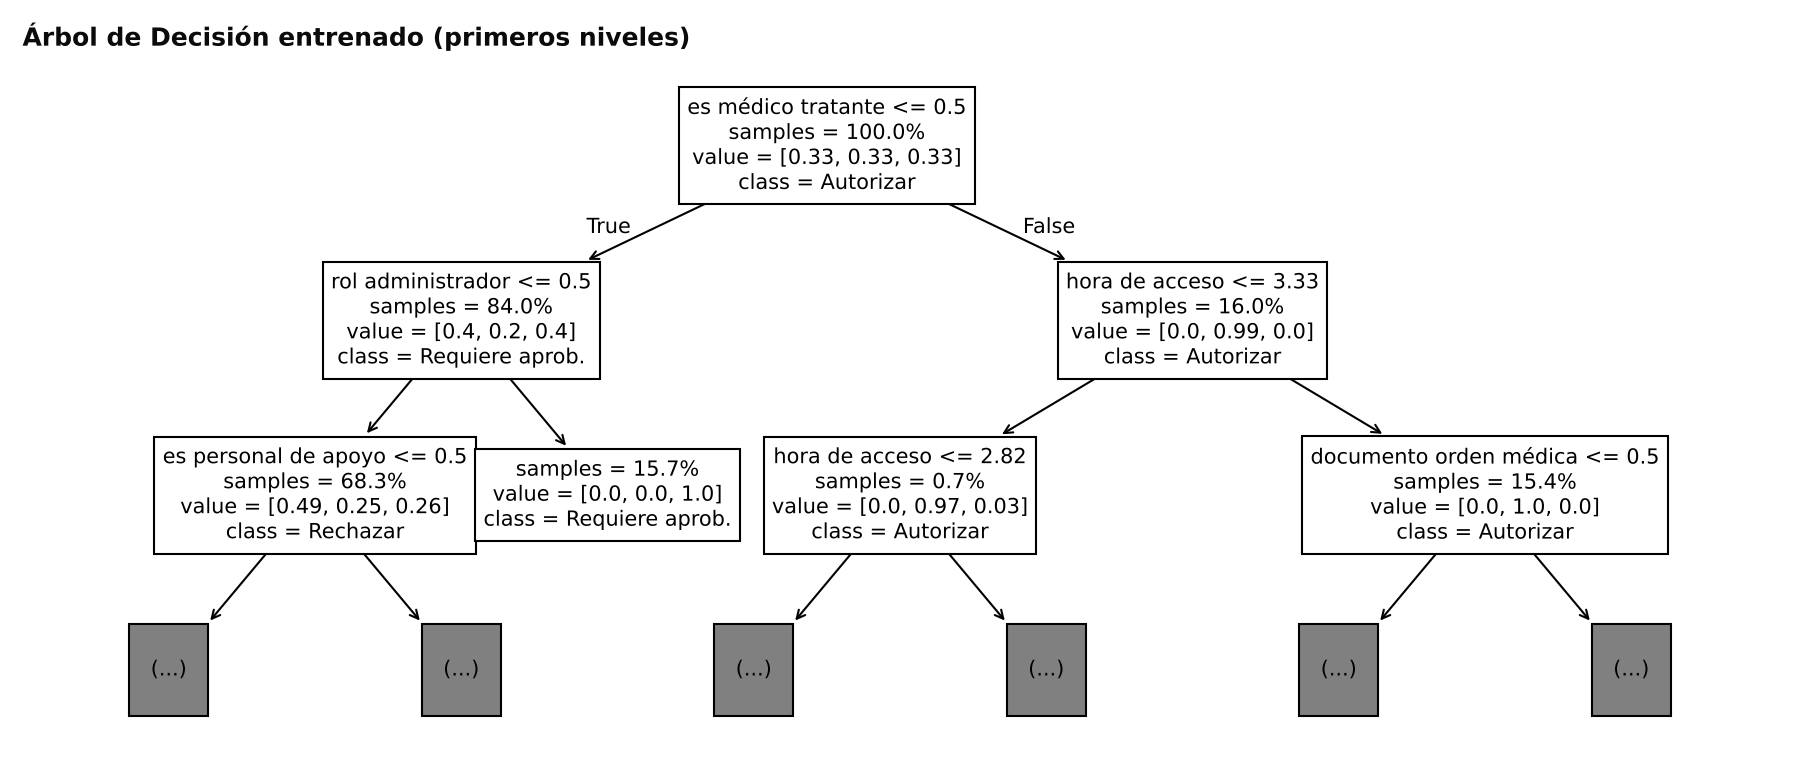

In [8]:
for f in ['matriz_confusion_arbol.png', 'matriz_confusion_logistica.png', 'matriz_confusion_isolation.png', 'curvas_roc.png',
          'curva_validacion_arbol.png', 'importancia_atributos.png', 'arbol_decision.png']:
    display(Image(filename=f'reports/figuras/{f}', width=620))

## 4. El agente en acción (Algoritmo 1)

In [9]:
from src.agente import AgenteAcceso
from src.auditoria import Auditoria
agente = AgenteAcceso(Auditoria('sqlite:///:memory:'))
casos = [
    dict(usuario_id=1, rol='MEDICO', tipo_documento='historia_clinica', relacion_paciente='medico_tratante', hora_acceso='10:30', frecuencia_accesos=5),
    dict(usuario_id=2, rol='ENFERMERIA', tipo_documento='historia_clinica', relacion_paciente='personal_apoyo', hora_acceso='11:00', frecuencia_accesos=8),
    dict(usuario_id=3, rol='ADMISION', tipo_documento='historia_clinica', relacion_paciente='sin_relacion', hora_acceso='12:00', frecuencia_accesos=3),
    dict(usuario_id=1, rol='MEDICO', tipo_documento='historia_clinica', relacion_paciente='medico_tratante', hora_acceso='14:00', frecuencia_accesos=70),
]
pd.DataFrame([{**c, **{k: r[k] for k in ['decision', 'score_anomalia', 'nivel_alerta', 'prob_legitimidad', 'tiempo_respuesta_ms', 'explicacion']}}
              for c in casos for r in [agente.procesar_solicitud(**c)]])

,usuario_id,rol,tipo_documento,relacion_paciente,hora_acceso,frecuencia_accesos,decision,score_anomalia,nivel_alerta,prob_legitimidad,tiempo_respuesta_ms,explicacion
0,1,MEDICO,historia_clinica,medico_tratante,10:30,5,AUTORIZAR,0.1664,NORMAL,NaN,26.07,Acceso autorizado a la historia clínica: eres ...
1,2,ENFERMERIA,historia_clinica,personal_apoyo,11:00,8,REQUIERE_APROBACION,0.1626,NORMAL,0.7454,26.21,Acceso pendiente de aprobación a la historia c...
2,3,ADMISION,historia_clinica,sin_relacion,12:00,3,RECHAZAR,0.2845,NORMAL,NaN,23.81,Acceso rechazado a la historia clínica: el per...
3,1,MEDICO,historia_clinica,medico_tratante,14:00,70,RECHAZAR,0.8768,CRITICO,NaN,23.18,Acceso bloqueado: se detectó un patrón de acce...


## 5. Evaluación con los escenarios de la Tabla 3

In [10]:
from src import evaluar
evaluar.main()
e = json.load(open('reports/evaluacion_escenarios.json', encoding='utf-8'))
pd.DataFrame(e['criterios'])

Criterio                                      Meta       Resultado                Cumple
------------------------------------------------------------------------------
Autorización correcta de accesos legítimos    ≥ 95 %     100.0 %                  Sí
Rechazo de accesos no autorizados             ≥ 95 %     100.0 %                  Sí
Detección de accesos anómalos (recall)        ≥ 90 %     87.0 %                   No
Control de roles diferenciados                100 %      100.0 %                  Sí
Manejo de casos excepcionales                 100 %      100.0 %                  Sí
Tiempo de respuesta (máximo)                  < 500 ms   52.4 ms (promedio 28.3 ms) Sí
Completitud de la auditoría                   100 %      100.0 %                  Sí
Interpretación del lenguaje natural           ≥ 90 %     100.0 %                  Sí
Exactitud global del agente (eventos normales): 100.00%
Alertas en eventos normales (falsos positivos): 0.00%
Anomalías finalmente autorizadas por el 

,criterio,meta,resultado,n,cumple
0,Autorización correcta de accesos legítimos,≥ 95 %,100.0 %,100,True
1,Rechazo de accesos no autorizados,≥ 95 %,100.0 %,100,True
2,Detección de accesos anómalos (recall),≥ 90 %,87.0 %,100,False
3,Control de roles diferenciados,100 %,100.0 %,20,True
4,Manejo de casos excepcionales,100 %,100.0 %,10,True
5,Tiempo de respuesta (máximo),< 500 ms,52.4 ms (promedio 28.3 ms),330,True
6,Completitud de la auditoría,100 %,100.0 %,330,True
7,Interpretación del lenguaje natural,≥ 90 %,100.0 %,40,True


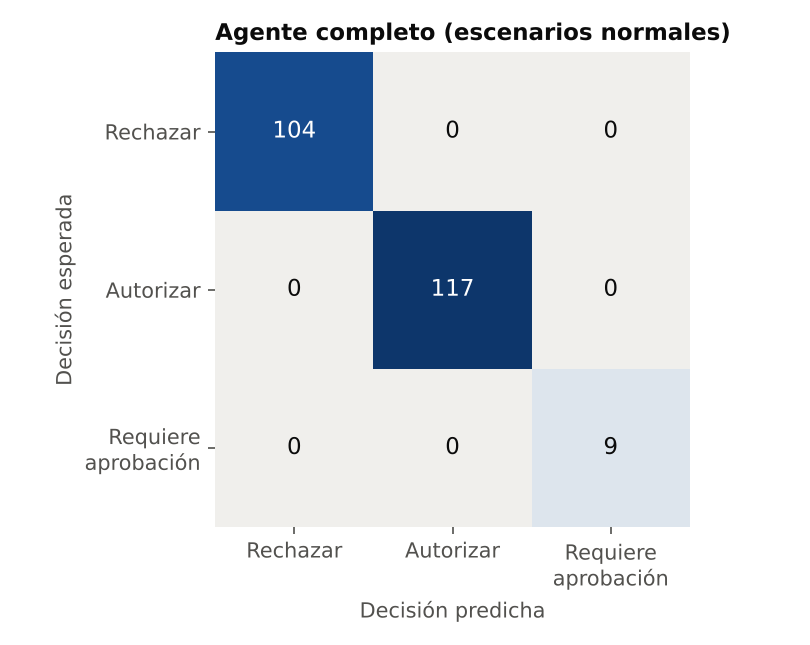

In [11]:
display(Image(filename='reports/figuras/matriz_confusion_agente.png', width=520))

## 6. Análisis complementario (capítulo IV)
Validación cruzada de 5 particiones, análisis de errores y comparación con la situación actual (sin control) y con un RBAC estático por rol.

In [12]:
from src import analisis_resultados
analisis_resultados.main()

{
  "validacion_cruzada_5": {
    "arbol_decision": {
      "exactitud": {
        "media": 0.985,
        "desv": 0.0021,
        "min": 0.9824,
        "max": 0.9887
      },
      "f1": {
        "media": 0.985,
        "desv": 0.0021,
        "min": 0.9824,
        "max": 0.9887
      }
    },
    "regresion_logistica": {
      "exactitud": {
        "media": 0.9846,
        "desv": 0.0017,
        "min": 0.9824,
        "max": 0.9874
      },
      "f1": {
        "media": 0.9846,
        "desv": 0.0017,
        "min": 0.9824,
        "max": 0.9874
      }
    },
    "isolation_forest": {
      "recall": {
        "media": 0.9117,
        "desv": 0.0286,
        "min": 0.8608,
        "max": 0.9404
      },
      "tasa_falsos_positivos": {
        "media": 0.0116,
        "desv": 0.0017,
        "min": 0.0084,
        "max": 0.0132
      }
    }
  },
  "analisis_errores_arbol": {
    "eventos_prueba": 1192,
    "errores": 28,
    "eventos_con_ruido": 28,
    "errores_en_eventos_co